# 03 · Decision Tree Classifier

A **Decision Tree** (max depth 5) predicts whether a patient has diabetes. I chose it because it is easy to explain, which matters in health care.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

df = pd.read_csv("../data/diabetes_cleaned.csv")
X = df.drop('Outcome', axis=1)
y = df['Outcome']
print(df.shape)

(768, 9)


### Train on 80%, test on 20%

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training: {len(X_train)} rows | Testing: {len(X_test)} rows")

model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"False negatives (missed diabetes): {cm[1][0]}")
print(f"Recall for diabetes: {cm[1][1] / (cm[1][0] + cm[1][1]):.0%}")

Training: 614 rows | Testing: 154 rows
Accuracy: 78.57%
False negatives (missed diabetes): 18
Recall for diabetes: 67%


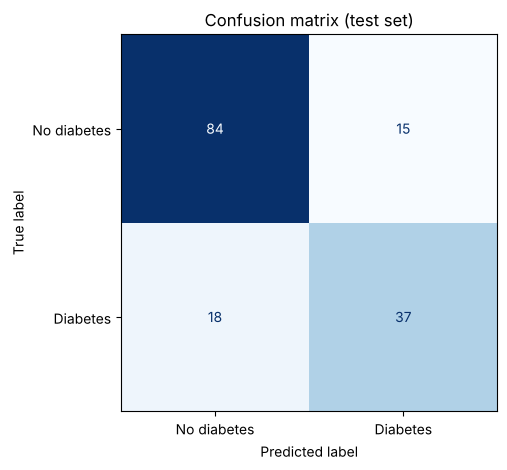

In [3]:
disp = ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"])
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig("../images/confusion_matrix.png", dpi=150)
plt.show()

### Which features matter most?

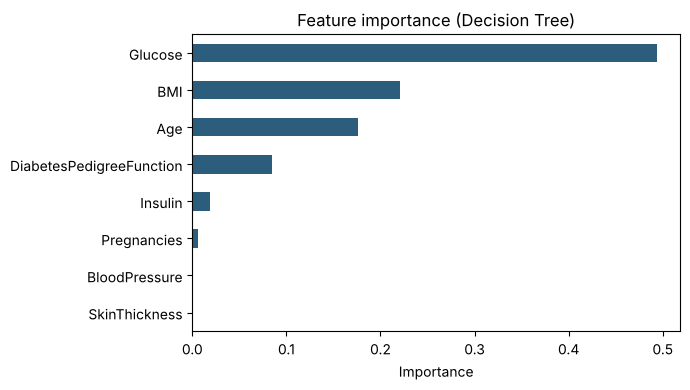

Glucose                     0.494
BMI                         0.221
Age                         0.176
DiabetesPedigreeFunction    0.084
Insulin                     0.019
Pregnancies                 0.006
SkinThickness               0.000
BloodPressure               0.000
dtype: float64

In [4]:
feat_imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
ax = feat_imp.plot(kind="barh", color="#2c5d7c", figsize=(7, 4))
ax.set_title("Feature importance (Decision Tree)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=150)
plt.show()
feat_imp.sort_values(ascending=False).round(3)

### Checking with a stratified split

The first split was not stratified, and the result comes from one split only. To check, I ran the model again with a **stratified** split (same share of diabetic patients in train and test).

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model_s = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
y_pred_s = model_s.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_s):.2%}")
print(classification_report(y_test, y_pred_s, target_names=["No Diabetes", "Diabetes"]))

Accuracy: 76.62%
              precision    recall  f1-score   support

 No Diabetes       0.85      0.78      0.81       100
    Diabetes       0.65      0.74      0.69        54

    accuracy                           0.77       154
   macro avg       0.75      0.76      0.75       154
weighted avg       0.78      0.77      0.77       154



### What I learned

- Accuracy alone is not enough in health care. **Missed diabetes cases (false negatives)** are the most serious errors, so recall matters.
- The result changes a little with a different split, so one number should not be treated as exact.
- Glucose, BMI and Age are the most important features, the same ones that matter most in the rule-based system.